# Solving the Blasius Equation with the Shooting Method


---

## 1. Problem Statement

When a uniform stream $U_\infty$ flows over a flat plate, a thin boundary layer forms near the surface. Using the similarity variable

$$\eta = y\sqrt{\frac{U_\infty}{\nu x}}, \qquad \frac{u}{U_\infty} = f'(\eta),$$

the boundary layer equations reduce to a single third-order ODE, the **Blasius equation**:

$$f''' + \tfrac{1}{2} f f'' = 0, \qquad 0 < \eta < \infty$$

with boundary conditions

$$f(0) = 0, \quad f'(0) = 0 \quad \text{(no slip, no suction)}, \qquad f'(\eta) \to 1 \text{ as } \eta \to \infty \quad \text{(free stream)}.$$

The catch is that this is a **boundary value problem**. Two conditions are given at the wall and one is given "at infinity". Runge–Kutta schemes need all three conditions at the starting point, so we can't integrate it directly. That's where the shooting method comes in.



In [1]:

import numpy as np
import matplotlib.pyplot as plt


## 2.Writing it as a First-Order System

Let $\mathbf{Y} = (Y_1, Y_2, Y_3)^T = (f,\ f',\ f'')^T$. Then

$$
\mathbf{Y}' = \mathbf{G}(\mathbf{Y}) =
\begin{pmatrix} Y_2 \\ Y_3 \\ -\tfrac{1}{2} Y_1 Y_3 \end{pmatrix}
$$

The system is autonomous (there's no explicit $\eta$ on the right-hand side), which keeps the code a little simpler.

For the stepping I'm using Kutta's third-order Runge–Kutta scheme:

$$
\begin{aligned}
k_1 &= G(Y_n) \\
k_2 &= G(Y_n + \tfrac{h}{2} k_1) \\
k_3 &= G(Y_n - h k_1 + 2h k_2) \\
Y_{n+1} &= Y_n + \tfrac{h}{6}(k_1 + 4k_2 + k_3)
\end{aligned}
$$

and later the classical RK4 scheme for comparison.

In [2]:

def G(Y):
    """
    Right-hand side of the Blasius system.
    Y = [f, f', f'']  ->  Y' = [f', f'', -0.5 * f * f'']
    """
    f, fp, fpp = Y
    return np.array([fp, fpp, -0.5 * f * fpp])


def rk3_step(Y, h):
    """One step of Kutta's third-order Runge-Kutta method."""
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y - h * k1 + 2 * h * k2)
    return Y + (h / 6) * (k1 + 4 * k2 + k3)


def rk4_step(Y, h):
    """One step of the classical fourth-order Runge-Kutta method."""
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y + 0.5 * h * k2)
    k4 = G(Y + h * k3)
    return Y + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)


def integrate(s, h, eta_inf, stepper):
    """
    March the IVP from eta = 0 to eta = eta_inf with a fixed step h.
    The missing initial condition f''(0) is set to the guess s.
    Returns the eta grid and the solution array Y (columns: f, f', f'').
    """
    n = int(round(eta_inf / h))            
    eta = np.linspace(0.0, n * h, n + 1)   
    Y = np.zeros((n + 1, 3))

    
    Y[0] = [0.0, 0.0, s]

    
    for i in range(n):
        Y[i + 1] = stepper(Y[i], h)

    return eta, Y

## 3.The Missing Initial Condition

At $\eta = 0$ we know $f(0)=0$ and $f'(0)=0$. What we **don't** know is $f''(0)$, which physically is the non-dimensional wall shear stress. That becomes our shooting parameter:

$$s = f''(0)$$

For any guess of $s$ we get a well-posed initial value problem. The job is to find the value of $s$ that makes $f'$ approach 1 far from the wall.

## 4.Choosing $\eta_\infty$ and Setting Up the Residual

We can't integrate to actual infinity, so we cut the domain off at a finite $\eta_\infty$ and apply the far-field condition there. The residual is

$$F(s;\eta_\infty) = f'(\eta_\infty; s) - 1$$

and we want $F(s) = 0$.

**Root finder:** I used the **secant method**. It doesn't need the derivative of $F$ (Newton would need extra sensitivity equations), and it converges much faster than bisection. The starting guesses are $s_0 = 0.1$ and $s_1 = 0.5$, and iteration stops when successive values differ by less than $10^{-12}$. That tolerance is far below the discretisation errors we'll measure, so it won't affect the convergence study.

In [3]:

def residual(s, h, eta_inf, stepper):
    """F(s) = f'(eta_inf; s) - 1. We want this to be zero."""
    _, Y = integrate(s, h, eta_inf, stepper)
    return Y[-1, 1] - 1.0


def secant(h, eta_inf, stepper, s0=0.1, s1=0.5, tol=1e-12, max_iter=50, verbose=False):
    """
    Find s = f''(0) such that F(s) = 0 using the secant method.
    Returns the converged s and the number of iterations taken.
    """
    F0 = residual(s0, h, eta_inf, stepper)
    F1 = residual(s1, h, eta_inf, stepper)

    for it in range(1, max_iter + 1):
        
        s2 = s1 - F1 * (s1 - s0) / (F1 - F0)

        if verbose:
            print(f"  iter {it:2d}:  s = {s2:.12f}   |ds| = {abs(s2 - s1):.2e}")

        
        if abs(s2 - s1) < tol:
            return s2, it

        # Shift the points along for the next iteration
        s0, F0 = s1, F1
        s1, F1 = s2, residual(s2, h, eta_inf, stepper)

    raise RuntimeError("Secant method did not converge")



print("Secant iterations (RK4, h = 0.1, eta_inf = 10):")
s, n_it = secant(0.1, 10.0, rk4_step, verbose=True)
print(f"\nConverged to s = {s:.10f} in {n_it} iterations")

Secant iterations (RK4, h = 0.1, eta_inf = 10):
  iter  1:  s = 0.354843623278   |ds| = 1.45e-01
  iter  2:  s = 0.330384782704   |ds| = 2.45e-02
  iter  3:  s = 0.332076148221   |ds| = 1.69e-03
  iter  4:  s = 0.332057361417   |ds| = 1.88e-05
  iter  5:  s = 0.332057345610   |ds| = 1.58e-08
  iter  6:  s = 0.332057345611   |ds| = 1.49e-13

Converged to s = 0.3320573456 in 6 iterations


In [4]:

S_LABEL = "f''(0)"   # column header for the printed tables

print(f"{'eta_inf':>8} | {S_LABEL:>14}")
print("-" * 26)

for eta_inf in [4, 6, 8, 10, 12, 15]:
    s, _ = secant(0.01, eta_inf, rk4_step)
    print(f"{eta_inf:8.0f} | {s:14.10f}")

 eta_inf |         f''(0)
--------------------------
       4 |   0.3527462535
       6 |   0.3325659312
       8 |   0.3320591917
      10 |   0.3320573372
      12 |   0.3320573362
      15 |   0.3320573362


**Observation:** at $\eta_\infty = 4$ the answer is clearly off (about 0.353) because we're forcing $f'=1$ while still inside the boundary layer. At $\eta_\infty = 8$ it's right to about five digits, and from $\eta_\infty = 10$ onwards the change is around $10^{-9}$, which is smaller than the RK errors we're about to study.

So I'm using **$\eta_\infty = 10$**. It's large enough, and since $10/0.4 = 25$, every step size in part (d) lands exactly on the end point.

In [5]:

ETA_INF = 10.0                         
STEPS   = [0.4, 0.2, 0.1, 0.05, 0.025] 
h_arr   = np.array(STEPS)               

## 5.Convergence Study with RK3

To measure the error we need a "true" value of $s$. Blasius has no closed-form solution, so I computed a reference value using RK4 on a very fine grid ($\Delta\eta = 0.001$) with the **same** $\eta_\infty$. Keeping $\eta_\infty$ the same matters, because otherwise the domain truncation error would get mixed into what should be a pure step-size error.

For each $\Delta\eta$ the error is

$$e(\Delta\eta) = |s_{\Delta\eta} - s_{\text{ref}}|$$

If the method is order $p$, then $e \approx C\,\Delta\eta^p$, so a log–log plot should give a straight line with slope $p$. I also compute the observed order between consecutive grids:

$$p_{\text{obs}} = \frac{\ln(e_{i}/e_{i+1})}{\ln(\Delta\eta_i/\Delta\eta_{i+1})}$$

In [8]:

s_ref, _ = secant(0.001, ETA_INF, rk4_step)
print(f"Reference value (RK4, h = 0.001): s_ref = {s_ref:.12f}")


def convergence_study(stepper, name):
    """
    Solve for s at every step size in STEPS, compute the error against
    s_ref, print a table with the observed order, and return the results.
    """
    s_vals, errs = [], []
    for h in STEPS:
        s, _ = secant(h, ETA_INF, stepper)
        s_vals.append(s)
        errs.append(abs(s - s_ref))

    
    print(f"\n{name} results")
    print(f"{'h':>7} | {S_LABEL:>14} | {'error':>10} | {'observed order':>14}")
    print("-" * 56)
    for i, h in enumerate(STEPS):
        if i == 0:
            p_str = "-"   
        else:
            p = np.log(errs[i - 1] / errs[i]) / np.log(STEPS[i - 1] / STEPS[i])
            p_str = f"{p:.3f}"
        print(f"{h:7.3f} | {s_vals[i]:14.10f} | {errs[i]:10.3e} | {p_str:>14}")

    
    slope = np.polyfit(np.log(STEPS), np.log(errs), 1)[0]
    print(f"\nLeast-squares slope over all points: {slope:.3f}")

    return np.array(s_vals), np.array(errs), slope



s_rk3, err_rk3, slope_rk3 = convergence_study(rk3_step, "RK3")

Reference value (RK4, h = 0.001): s_ref = 0.332057337204

RK3 results
      h |         f''(0) |      error | observed order
--------------------------------------------------------
  0.400 |   0.3319771448 |  8.019e-05 |              -
  0.200 |   0.3320495982 |  7.739e-06 |          3.373
  0.100 |   0.3320565334 |  8.038e-07 |          3.267
  0.050 |   0.3320572476 |  8.961e-08 |          3.165
  0.025 |   0.3320573267 |  1.050e-08 |          3.093

Least-squares slope over all points: 3.223


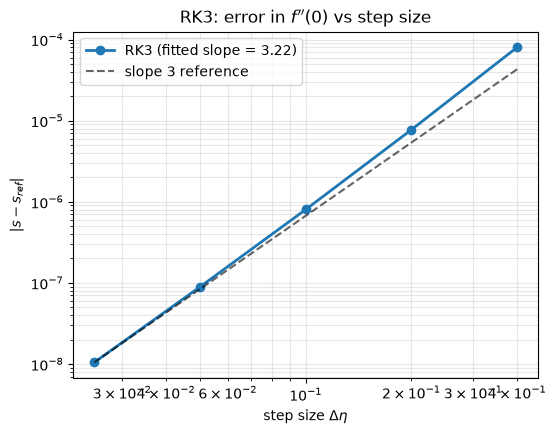

In [9]:

plt.figure(figsize=(6, 4.5))

plt.loglog(h_arr, err_rk3, "o-", lw=2, label=f"RK3 (fitted slope = {slope_rk3:.2f})")


plt.loglog(h_arr, err_rk3[-1] * (h_arr / h_arr[-1])**3, "k--", alpha=0.6, label="slope 3 reference")

plt.xlabel(r"step size $\Delta\eta$")
plt.ylabel(r"$|s - s_{ref}|$")
plt.title("RK3: error in $f''(0)$ vs step size")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

**What the RK3 results show:** the error drops by roughly a factor of 8 to 10 every time the step is halved. The observed order starts a bit above 3 on the coarse grids (around 3.4) and settles towards **3.0** as $\Delta\eta$ gets smaller. That's expected: on coarse grids the higher-order error terms still contribute, and once we're in the asymptotic range the leading $\Delta\eta^3$ term dominates. The line on the log–log plot runs parallel to the slope-3 guide, so RK3 is behaving as a third-order method.

## 6.Profiles of $f$, $f'$ and $f''$ (RK3)

Using the converged $s$ from the finest RK3 grid, I integrated once more and plotted the three profiles.

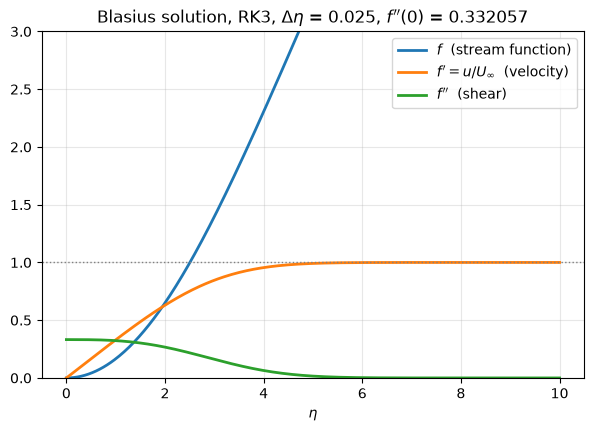

f' first reaches 0.99 at eta ~ 4.925
Far-field offset (eta - f) at eta_inf: 1.7208


In [10]:

def plot_profiles(stepper, h, name):
    """Solve for s, integrate once more with it, and plot f, f', f''."""
    s, _ = secant(h, ETA_INF, stepper)
    eta, Y = integrate(s, h, ETA_INF, stepper)

    plt.figure(figsize=(7, 4.5))
    plt.plot(eta, Y[:, 0], lw=2, label=r"$f$  (stream function)")
    plt.plot(eta, Y[:, 1], lw=2, label=r"$f' = u/U_\infty$  (velocity)")
    plt.plot(eta, Y[:, 2], lw=2, label=r"$f''$  (shear)")
    plt.axhline(1.0, color="gray", ls=":", lw=1)   # free-stream level f' = 1

    plt.xlabel(r"$\eta$")
    plt.ylim(0, 3)
    plt.title(f"Blasius solution, {name}, $\\Delta\\eta$ = {h}, $f''(0)$ = {s:.6f}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    
    idx = np.argmax(Y[:, 1] >= 0.99)
    print(f"f' first reaches 0.99 at eta ~ {eta[idx]:.3f}")

    
    print(f"Far-field offset (eta - f) at eta_inf: {eta[-1] - Y[-1, 0]:.4f}")

    return eta, Y


eta3, Y3 = plot_profiles(rk3_step, 0.025, "RK3")


- $f'$ (the velocity) starts at 0 on the wall and levels off smoothly at 1. It reaches 99% of the free-stream speed at about $\eta \approx 4.9$, which matches the textbook boundary layer thickness $\delta \approx 5\sqrt{\nu x/U_\infty}$.
- $f''$ (the shear) is largest at the wall, where it equals $s \approx 0.332$, and decays to practically zero outside the boundary layer. It never increases, because $f''' = -\tfrac12 f f'' \le 0$.
- $f$ grows roughly like $\tfrac{s}{2}\eta^2$ near the wall and then becomes a straight line of slope 1 further out, $f \approx \eta - 1.72$. That offset of about 1.72 is the displacement thickness in similarity units.

## 7.Repeating with RK4

Same procedure, same $\eta_\infty$, same step sizes. Only the stepper changes.

In [11]:

s_rk4, err_rk4, slope_rk4 = convergence_study(rk4_step, "RK4")


RK4 results
      h |         f''(0) |      error | observed order
--------------------------------------------------------
  0.400 |   0.3320588158 |  1.479e-06 |              -
  0.200 |   0.3320574575 |  1.202e-07 |          3.620
  0.100 |   0.3320573456 |  8.407e-09 |          3.838
  0.050 |   0.3320573378 |  5.535e-10 |          3.925
  0.025 |   0.3320573372 |  3.548e-11 |          3.964

Least-squares slope over all points: 3.846


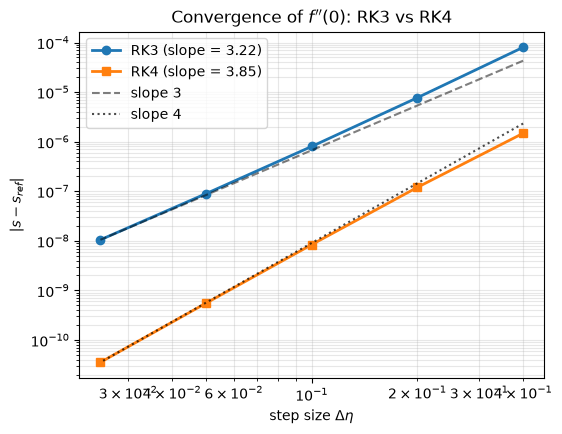

In [12]:

plt.figure(figsize=(6, 4.5))

plt.loglog(h_arr, err_rk3, "o-", lw=2, label=f"RK3 (slope = {slope_rk3:.2f})")
plt.loglog(h_arr, err_rk4, "s-", lw=2, label=f"RK4 (slope = {slope_rk4:.2f})")

# Slope-3 and slope-4 guide lines
plt.loglog(h_arr, err_rk3[-1] * (h_arr / h_arr[-1])**3, "k--", alpha=0.5, label="slope 3")
plt.loglog(h_arr, err_rk4[-1] * (h_arr / h_arr[-1])**4, "k:",  alpha=0.7, label="slope 4")

plt.xlabel(r"step size $\Delta\eta$")
plt.ylabel(r"$|s - s_{ref}|$")
plt.title("Convergence of $f''(0)$: RK3 vs RK4")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

**RK4 results:** the observed order goes from about 3.6 on the coarsest pair up to about **3.96** on the finest pair, heading towards 4 as expected. At every step size the RK4 error is roughly two orders of magnitude smaller than RK3, so the extra function evaluation per step is clearly worth it. At $\Delta\eta = 0.025$ RK4 is already accurate to around $10^{-11}$.

One thing I checked: the reference value itself has some error (RK4 at $h = 0.001$, roughly $10^{-14}$), but that's still a few orders below the smallest error in the table, so it doesn't bend the convergence line.

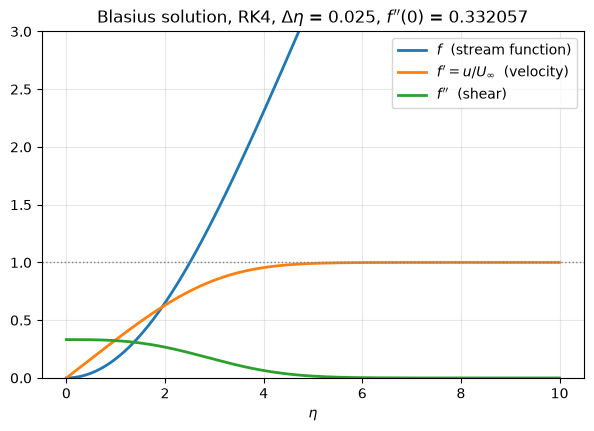

f' first reaches 0.99 at eta ~ 4.925
Far-field offset (eta - f) at eta_inf: 1.7208
Max difference in f' between RK3 and RK4 profiles: 3.48e-08


In [13]:

eta4, Y4 = plot_profiles(rk4_step, 0.025, "RK4")

max_diff = np.max(np.abs(Y3[:, 1] - Y4[:, 1]))
print(f"Max difference in f' between RK3 and RK4 profiles: {max_diff:.2e}")

As expected, the RK4 profiles look identical to the RK3 ones. The largest pointwise difference in $f'$ is far too small to see on a plot.

## 8.Check Against the Known Value

The accepted value for the Blasius wall shear parameter is $f''(0) \approx 0.33206$. The assignment asks for agreement with 0.332 to three digits, so let's check every case.

In [14]:

print(f"{'Method':<8} {'h':>6}   {S_LABEL:>14}   {'rounded':>8}   check")
print("-" * 50)

for name, vals in [("RK3", s_rk3), ("RK4", s_rk4)]:
    for h, s in zip(STEPS, vals):
        ok = "OK" if round(s, 3) == 0.332 else "FAIL"
        print(f"{name:<8} {h:6.3f}   {s:14.10f}   {round(s, 3):8.3f}   {ok}")

Method        h           f''(0)    rounded   check
--------------------------------------------------
RK3       0.400     0.3319771448      0.332   OK
RK3       0.200     0.3320495982      0.332   OK
RK3       0.100     0.3320565334      0.332   OK
RK3       0.050     0.3320572476      0.332   OK
RK3       0.025     0.3320573267      0.332   OK
RK4       0.400     0.3320588158      0.332   OK
RK4       0.200     0.3320574575      0.332   OK
RK4       0.100     0.3320573456      0.332   OK
RK4       0.050     0.3320573378      0.332   OK
RK4       0.025     0.3320573372      0.332   OK


Every case rounds to **0.332**, even RK3 at the coarsest step $\Delta\eta = 0.4$, so the check passes. The converged value from this work is

$$f''(0) = 0.332057\ldots$$

which agrees with the classical result.

## 9. Summary

| Item | Result |
|---|---|
| Shooting parameter | $s = f''(0)$ |
| Far-field cut-off | $\eta_\infty = 10$ (going further changes $s$ by about $10^{-9}$) |
| Root finder | Secant method, tolerance $10^{-12}$, about 6 iterations |
| RK3 observed order | about 3.4 down to 3.1, approaching **3** |
| RK4 observed order | about 3.6 up to 3.96, approaching **4** |
| Converged $f''(0)$ | **0.332057** |
| 99% boundary layer edge | $\eta \approx 4.9$ |

**Takeaways:**
- The shooting method works well for Blasius. $F(s)$ is smooth and monotonic in $s$, so the secant method converges in a handful of iterations even from loose starting guesses.
- The cut-off $\eta_\infty$ is a separate source of error from the step size. It's worth checking it on its own before the convergence study, otherwise the two errors get mixed and the measured slopes come out wrong.
- Both RK schemes show their theoretical order of accuracy. On coarse grids the observed order is slightly off because we aren't in the asymptotic range yet, but it settles as $\Delta\eta \to 0$.
- RK4 costs one more function evaluation per step than RK3, but here it gives roughly 100 times smaller error at the same step size, so it's the better choice.